# Análisis de sentimiento en reseñas — WeLoveReviews

## 0. Objetivos

**Cliente:** Harbor House Café, una cafetería con una puntuación media de **4.5 / 5** estrellas.

**Pregunta de la account manager:**
> ¿Cuántas de las 500 reseñas escritas se leen como **positivas, neutrales o negativas**, y esa distribución **coincide** con el promedio de 4.5 estrellas? Si no coincide, ¿de dónde viene la diferencia?

**Cómo lo vamos a responder:**
1. Explorar las reseñas (EDA) y decidir si hace falta limpiar algo.
2. Pasar las 500 reseñas por un modelo preentrenado de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`), sin entrenar nada.
3. Comparar el sentimiento que lee el modelo con las estrellas que pusieron los clientes.
4. Revisar a mano dónde falla el modelo, sobre todo los **falsos negativos** (el cliente puso 4–5 estrellas y el modelo lee 1–2).
5. Sacar una conclusión en lenguaje claro para la account manager.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

# El notebook vive en src/; las rutas se calculan desde la raíz del repo.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_PATH = ROOT / "data" / "raw" / "reviews.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "reviews_with_sentiment.csv"
sys.path.insert(0, str(ROOT / "src"))
RAW_PATH

PosixPath('/workspaces/sentiment-analysis-reviews/data/raw/reviews.csv')

## 1. EDA — exploración del dataset

Empezamos por lo básico: tamaño, tipos de datos y valores faltantes.

In [2]:
df_raw = pd.read_csv(RAW_PATH)
print("Forma:", df_raw.shape)
print()
print(df_raw.dtypes)
print()
print("Valores faltantes por columna:")
print(df_raw.isna().sum())
df_raw.head()

Forma: (500, 3)

review_id       int64
rating          int64
review_text    object
dtype: object

Valores faltantes por columna:
review_id      0
rating         0
review_text    0
dtype: int64


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.


500 filas y 3 columnas, sin valores faltantes. Ahora miramos **cómo se reparten las estrellas** y comprobamos que la media es realmente 4.5.

,reseñas,%
rating,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Media de estrellas: 4.50


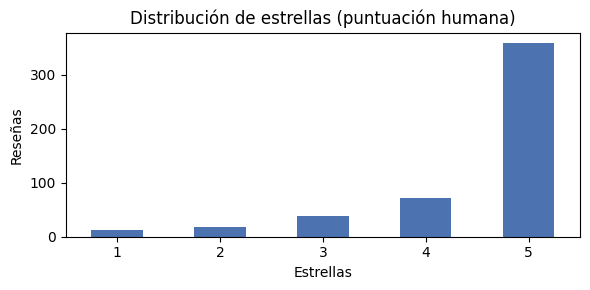

In [3]:
rating_counts = df_raw["rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df_raw) * 100).round(1)
display(pd.DataFrame({"reseñas": rating_counts, "%": rating_pct}))
print(f"Media de estrellas: {df_raw['rating'].mean():.2f}")

ax = rating_counts.plot(kind="bar", color="#4C72B0", figsize=(6, 3))
ax.set_title("Distribución de estrellas (puntuación humana)")
ax.set_xlabel("Estrellas")
ax.set_ylabel("Reseñas")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

La media es exactamente **4.50**, pero la distribución está muy sesgada: **72 %** de las reseñas son de 5 estrellas y solo un 6 % son de 1–2. Aplicando la misma regla de bandas que usaremos para el modelo, las estrellas humanas ya nos dan una línea base:

In [4]:
def to_band(stars):
    return "negativo" if stars <= 2 else ("neutral" if stars == 3 else "positivo")

human_bands = df_raw["rating"].map(to_band).value_counts(normalize=True).mul(100).round(1)
human_bands.reindex(["positivo", "neutral", "negativo"]).to_frame("% según estrellas humanas")

,% según estrellas humanas
rating,
positivo,86.4
neutral,7.6
negativo,6.0


Pasamos al texto. La longitud importa por dos razones: el modelo BERT corta a 512 tokens, y textos muy cortos o vacíos darían predicciones poco fiables.

In [5]:
df_raw["n_chars"] = df_raw["review_text"].str.len()
df_raw["n_words"] = df_raw["review_text"].str.split().str.len()
display(df_raw[["n_chars", "n_words"]].describe().round(1))
display(df_raw.groupby("rating")[["n_chars", "n_words"]].mean().round(1))

,n_chars,n_words
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


,n_chars,n_words
rating,,
1,175.3,30.2
2,151.3,26.4
3,152.7,26.8
4,182.3,30.5
5,170.4,29.2


Todas las reseñas son cortas (14–42 palabras), muy por debajo del límite de 512 tokens: no hace falta truncar ni partir textos. La longitud tampoco cambia mucho según las estrellas.

Vemos una pequeña muestra de cada nivel de estrellas:

In [6]:
for stars in range(1, 6):
    print(f"--- {stars} estrella(s) ---")
    for text in df_raw.loc[df_raw["rating"] == stars, "review_text"].head(2):
        print("  •", text)

--- 1 estrella(s) ---
  • Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.
  • Came to Harbor House Café for a birthday brunch. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
--- 2 estrella(s) ---
  • Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.
  • Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.
--- 3 estrella(s) ---
  • Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.
  • Stopped by Harbor House Café for the first time. The menu is fine but a bit repetitive. The cashier was rude when i ask

Las reseñas parecen **construidas a partir de frases que se repiten** ("Will definitely be back!", "Five stars without hesitation."…). Lo comprobamos partiendo cada reseña en frases:

In [7]:
sentences = (
    df_raw.assign(sentence=df_raw["review_text"].str.split(r"(?<=[.!?])\s+"))
    .explode("sentence")
    .reset_index(drop=True)
)
print("Frases distintas en todo el dataset:", sentences["sentence"].nunique())
print("Reseñas con texto duplicado exacto:", df_raw["review_text"].duplicated().sum())
print("review_id duplicados:", df_raw["review_id"].duplicated().sum())
sentences["sentence"].value_counts().head(10)

Frases distintas en todo el dataset: 69
Reseñas con texto duplicado exacto: 7
review_id duplicados: 0


sentence
This is now my go-to spot.                                     92
Will definitely be back!                                       85
Five stars without hesitation.                                 84
Came to Harbor House Café for a birthday brunch.               79
Tried Harbor House Café after seeing it recommended online.    76
Already planning my next visit.                                75
Regular customer at Harbor House Café here.                    74
Grabbed a quick coffee at Harbor House Café this morning.      73
Stopped by Harbor House Café for the first time.               70
Highly recommend to anyone in the area.                        69
Name: count, dtype: int64

Solo hay ~70 frases distintas combinadas en 500 reseñas. Un detalle importante para más adelante: algunas frases **mezclan una queja con un cierre positivo** (patrón "X, but overall a solid experience"). Miramos en qué estrellas aparecen:

In [8]:
mixed = sentences[sentences["sentence"].str.contains(", but ", regex=False)]
pd.crosstab(mixed["sentence"], mixed["rating"])

rating,3,4,5
sentence,,,
"Average service, no complaints, but overall a solid experience.",0,12,0
"Nobody checked on us the entire meal, but honestly the food made up for it.",0,0,2
"Our server got our order wrong twice, but honestly the food made up for it.",0,0,5
"Service was fine, nothing memorable, but overall a solid experience.",0,17,0
"The cashier was rude when i asked about the menu, but honestly the food made up for it.",0,0,3
"The staff seemed annoyed to be there, but honestly the food made up for it.",0,0,4
"The staff seemed annoyed to be there, but overall a solid experience.",0,13,0
"The staff were polite but a bit slow, but overall a solid experience.",0,16,0
"We waited 25 minutes just to get water, but honestly the food made up for it.",0,0,7


### Insights de la EDA

1. **Datos limpios:** 500 reseñas, sin nulos, sin `review_id` repetidos y todas en inglés.
2. **La media de 4.5 esconde una distribución muy sesgada:** 86 % de reseñas con 4–5 estrellas, 8 % con 3 y 6 % con 1–2.
3. **Textos cortos y repetitivos:** ~70 frases distintas recombinadas. Hay 7 textos duplicados exactos, pero son clientes distintos (`review_id` distinto).
4. **Señal de riesgo para el modelo:** las frases mixtas ("*queja*, but overall a solid experience" y "*queja*, but honestly the food made up for it") aparecen **solo en reseñas de 4 y 5 estrellas**. Es justo el tipo de texto que un modelo entrenado con reseñas de productos podría leer como negativo.
5. **Dominio de servicio:** se habla de personal, esperas, ambiente y precio, no de un producto. Esto confirma el desajuste de dominio que avisa el enunciado.

### Limpieza propuesta

- `strip()` de espacios en los textos, como medida de seguridad.
- **No** eliminamos duplicados: son reseñas reales de clientes distintos y la account manager necesita una predicción para **las 500**.
- **No** traducimos ni normalizamos el texto: el modelo es *uncased* y multilingüe, así que el inglés tal cual le va bien.

In [9]:
df = df_raw[["review_id", "rating", "review_text"]].copy()
df["review_text"] = df["review_text"].astype(str).str.strip()
assert len(df) == 500 and df["review_text"].str.len().min() > 0
df.shape

(500, 3)

## 2. Plan de acción y elección del modelo

**Modelo:** `nlptown/bert-base-multilingual-uncased-sentiment`, fijado al commit `8f6f4e3`.
- Es un BERT multilingüe fine-tuneado con reseñas de **productos**, que predice de **1 a 5 estrellas**. Por eso se compara directamente con la puntuación humana.
- Lo usamos tal cual, sin entrenar. Las reseñas caben de sobra en 512 tokens (insight 3).
- Riesgo conocido: el desajuste de dominio (producto frente a servicio) y las frases mixtas (insights 4 y 5). Por eso medimos los falsos negativos y revisamos una muestra a mano.

**Mapeo a bandas:**

| Predicción del modelo | Banda |
|---|---|
| 1–2 estrellas | Negativo |
| 3 estrellas | Neutral |
| 4–5 estrellas | Positivo |

**Reglas de integración:**
- Se carga con `pipeline()` → los pesos van a la caché de Hugging Face, **no al repo**.
- Nombre **y revisión** fijados: si alguien clona el repo dentro de un año, obtiene exactamente el mismo modelo.
- El modelo se carga **una sola vez**, antes de la inferencia, y se pasan las 500 reseñas **en lotes**.

## 3. Inferencia sobre las 500 reseñas

In [10]:
from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"  # commit fijado en el Hub

t0 = time.perf_counter()
classifier = pipeline("sentiment-analysis", model=MODEL_NAME, revision=MODEL_REVISION)  # UNA sola vez
print(f"Modelo cargado en {time.perf_counter() - t0:.1f}s")

Device set to use cpu


Modelo cargado en 0.8s


Con el modelo ya en memoria, pasamos todas las reseñas en lotes de 32. No hay ningún `pipeline()` dentro de un bucle.

In [11]:
t0 = time.perf_counter()
results = classifier(df["review_text"].tolist(), batch_size=32, truncation=True)
print(f"{len(results)} predicciones en {time.perf_counter() - t0:.1f}s")

df["pred_stars"] = [int(r["label"].split()[0]) for r in results]   # '4 stars' -> 4
df["pred_score"] = [round(r["score"], 4) for r in results]
df["pred_band"] = df["pred_stars"].map(to_band)
df["rating_band"] = df["rating"].map(to_band)
df["false_negative"] = (df["rating"] >= 4) & (df["pred_stars"] <= 2)

assert df["pred_stars"].notna().all() and len(df) == 500
df.head()

500 predicciones en 37.1s


,review_id,rating,review_text,pred_stars,pred_score,pred_band,rating_band,false_negative
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,0.7170,positivo,positivo,False
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...,5,0.9822,positivo,positivo,False
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...,5,0.6623,positivo,positivo,False
3,4,5,Visited Harbor House Café last weekend. The staff were warm and attentive. The music and decor set the perfect mood. Worth every penny. Five stars without hesitation.,5,0.9895,positivo,positivo,False
4,5,5,Grabbed a quick coffee at Harbor House Café this morning. They went out of their way to accommodate my allergy. The food was absolutely delicious. Five stars without hesitation.,5,0.9829,positivo,positivo,False


## 4. Desglose del sentimiento frente al promedio de 4.5 estrellas

La pregunta principal: ¿qué porcentaje de reseñas lee el modelo como positivo, neutral y negativo, y cómo se compara con las estrellas que pusieron los clientes?

,% según el modelo,% según estrellas humanas,diferencia (pp)
positivo,82.4,86.4,-4.0
neutral,8.2,7.6,0.6
negativo,9.4,6.0,3.4


Media de estrellas humanas:   4.50
Media de estrellas del modelo: 4.40


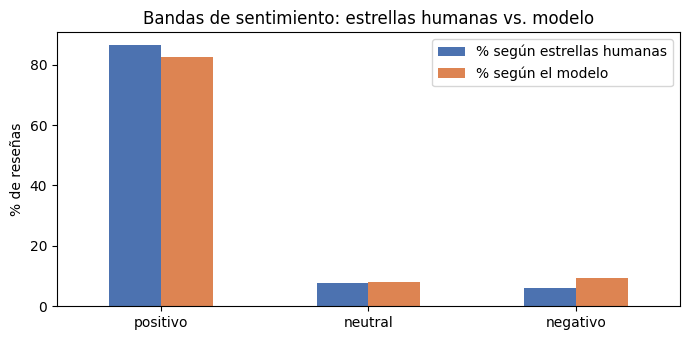

In [12]:
order = ["positivo", "neutral", "negativo"]
comparison = pd.DataFrame({
    "% según el modelo": df["pred_band"].value_counts(normalize=True).mul(100).round(1),
    "% según estrellas humanas": df["rating_band"].value_counts(normalize=True).mul(100).round(1),
}).reindex(order).fillna(0)
comparison["diferencia (pp)"] = (comparison["% según el modelo"] - comparison["% según estrellas humanas"]).round(1)
display(comparison)

print(f"Media de estrellas humanas:   {df['rating'].mean():.2f}")
print(f"Media de estrellas del modelo: {df['pred_stars'].mean():.2f}")

ax = comparison[["% según estrellas humanas", "% según el modelo"]].plot(
    kind="bar", figsize=(7, 3.5), color=["#4C72B0", "#DD8452"])
ax.set_title("Bandas de sentimiento: estrellas humanas vs. modelo")
ax.set_ylabel("% de reseñas")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Para ver **dónde** se separan el modelo y los clientes, cruzamos estrellas humanas (filas) con estrellas predichas (columnas):

In [13]:
display(pd.crosstab(df["rating"], df["pred_stars"], rownames=["estrellas humanas"], colnames=["estrellas modelo"], margins=True))
agreement = (df["rating_band"] == df["pred_band"]).mean() * 100
print(f"Coincidencia de banda humano vs. modelo: {agreement:.1f} %")

estrellas modelo,1,2,3,4,5,All
estrellas humanas,,,,,,
1,3,9,0,0,0,12
2,7,9,2,0,0,18
3,0,3,35,0,0,38
4,1,0,3,47,21,72
5,11,4,1,9,335,360
All,22,25,41,56,356,500


Coincidencia de banda humano vs. modelo: 95.0 %


### Qué nos dice el desglose

| | Positivo | Neutral | Negativo |
|---|---|---|---|
| Según las estrellas de los clientes | 86.4 % | 7.6 % | 6.0 % |
| Según el texto (modelo) | 82.4 % | 8.2 % | 9.4 % |

- **La distribución sí coincide en lo grande con el 4.5:** el modelo lee **más de 8 de cada 10 reseñas como positivas**, y la media de estrellas que predice (**4.40**) está a solo 0.1 del 4.50 real. Humano y modelo coinciden en la banda en un **95 %** de las reseñas.
- **La diferencia está en la banda negativa:** el modelo cuenta un **9.4 %** de negativas frente al 6 % de las estrellas (+3.4 puntos). En la tabla cruzada se ve de dónde sale: **16 reseñas de 4–5 estrellas** que el modelo pone en 1–2 estrellas (esquina inferior izquierda). Si quitamos esos 16 casos, el % negativo del modelo bajaría a ~6 %, igual que el de las estrellas.
- Las reseñas de 3 estrellas se leen casi todas como neutrales (35 de 38). Las de 1–2 se leen todas como negativas, salvo 2 que el modelo deja en neutral.

**Conclusión parcial:** el texto **no contradice** el 4.5. La diferencia viene de un grupo pequeño de errores del modelo, no de clientes insatisfechos que ponen muchas estrellas. Lo comprobamos a continuación.

## 5. Falsos negativos

Definición: el cliente puso **4–5 estrellas** pero el modelo predice **1–2** (banda negativa). Estos son los casos que más daño harían en el reporte: un cliente contento contado como insatisfecho.

In [14]:
fn = df[df["false_negative"]]
print(f"Falsos negativos: {len(fn)} de {(df['rating'] >= 4).sum()} reseñas con 4–5 estrellas "
      f"({len(fn) / (df['rating'] >= 4).sum() * 100:.1f} %)")
print()
print("Por estrellas humanas:", fn["rating"].value_counts().sort_index().to_dict())
fn[["review_id", "rating", "pred_stars", "pred_score", "review_text"]].head(10)

Falsos negativos: 16 de 432 reseñas con 4–5 estrellas (3.7 %)

Por estrellas humanas: {4: 1, 5: 15}


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.4443,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.3893,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.2679,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.3247,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.2751,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.3685,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.3492,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my ne..."
253,254,5,1,0.3641,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1,0.4091,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1,0.6077,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


Para encontrar el **patrón común**, comparamos qué frases aparecen en los falsos negativos frente al resto de reseñas de 4–5 estrellas:

In [15]:
pos = df[df["rating"] >= 4].copy()
pos_sent = pos.assign(sentence=pos["review_text"].str.split(r"(?<=[.!?])\s+")).explode("sentence").reset_index(drop=True)
by_sentence = (
    pos_sent.groupby("sentence")["false_negative"]
    .agg(reseñas="count", falsos_negativos="sum")
)
by_sentence["% FN cuando aparece"] = (by_sentence["falsos_negativos"] / by_sentence["reseñas"] * 100).round(1)
by_sentence.sort_values(["falsos_negativos", "% FN cuando aparece"], ascending=False).head(12)

,reseñas,falsos_negativos,% FN cuando aparece
sentence,,,
Every dish was bursting with flavor.,41,12,29.3
Already planning my next visit.,75,11,14.7
Stopped by Harbor House Café for the first time.,61,6,9.8
Tried Harbor House Café after seeing it recommended online.,68,6,8.8
They went out of their way to accommodate my allergy.,38,4,10.5
Will definitely be back!,85,4,4.7
The team clearly cares about the customers.,49,3,6.1
Service was fast and friendly.,56,3,5.4
Our server remembered our names by the second visit.,47,2,4.3


Además de los falsos negativos "duros" (1–2 estrellas), miramos también las reseñas de 4–5 estrellas que el modelo deja en **neutral (3)**. No entran en la definición, pero también bajan el % positivo del reporte:

In [16]:
soft = df[(df["rating"] >= 4) & (df["pred_stars"] == 3)]
print(f"Reseñas de 4–5 estrellas leídas como neutrales: {len(soft)}")
soft[["review_id", "rating", "pred_stars", "review_text"]].head(8)

Reseñas de 4–5 estrellas leídas como neutrales: 4


,review_id,rating,pred_stars,review_text
146,147,4,3,"Stopped by Harbor House Café for the first time. The seasonal menu never disappoints. Service was fine, nothing memorable, but overall a solid experience. Might give it another shot."
252,253,4,3,"Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Average service, no complaints, but overall a solid experience. This is now my go-to spot."
463,464,4,3,"Regular customer at Harbor House Café here. Every dish was bursting with flavor. Service was fine, nothing memorable, but overall a solid experience. Already planning my next visit."
476,477,5,3,"Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. We waited 25 minutes just to get water, but honestly the food made up for it. Already planning..."


### Patrón de los falsos negativos e hipótesis

**Qué vemos:**
- Hay **16 falsos negativos** de 432 reseñas con 4–5 estrellas (**3.7 %**). 15 son de 5 estrellas.
- Leídas a mano, **las 16 son claramente positivas**: elogios a la comida, al personal y ganas de volver. Ninguna es un cliente descontento "disfrazado".
- El modelo está **poco seguro** en ellas: su confianza media es ~0.38, frente a ~0.73 en el resto de reseñas positivas.
- Hay **dos frases que se repiten**:
  - **"Every dish was bursting with flavor."** aparece en **12 de los 16**. Cuando esta frase está en una reseña positiva, el 29 % de las veces acaba como falso negativo.
  - **"They went out of their way to accommodate my allergy."** aparece en otros 4.
- La sospecha de la EDA (las frases mixtas tipo "*queja*, but overall a solid experience") **no se cumplió**: de 90 reseñas positivas con una frase mixta, solo 2 acaban como falso negativo. El modelo entiende bien el "pero al final bien".

**Hipótesis: desajuste de dominio (producto frente a servicio).** El modelo aprendió de reseñas de **productos**. En ese mundo:
- *"burst / bursting"* suele significar que algo **se rompió o se reventó** (un envase o una costura). Es vocabulario de queja. En una cafetería, *"bursting with flavor"* es un elogio, pero el modelo no tiene ese contexto.
- *"allergy"* en una reseña de producto suele ser **"me dio alergia"**, que es una queja grave. En un servicio, *"accommodate my allergy"* es lo contrario: el personal se preocupó por el cliente.

Es decir, el modelo reacciona a **palabras sueltas** que en su dominio de origen son negativas, aunque aquí estén en frases positivas. Esto es una hipótesis: no podemos ver el dataset de entrenamiento del modelo. Pero que el error esté concentrado en dos frases concretas, y que el modelo dude tanto en esas reseñas, encaja con ella.

## 6. Muestra manual (20 reseñas)

Elegimos 20 reseñas con semilla fija (`random_state=7`): **3 por cada nivel de estrellas** (15), para que estén también las minoritarias (1–3), más **5 falsos negativos** al azar para mirarlos de cerca. Las leímos una a una. `mi_lectura` es la banda que le daríamos a mano y `nota_manual` explica si la predicción tiene sentido.

In [17]:
# Cómo se eligieron (semilla fija):
#   fn_ids = df[df["false_negative"]].sample(5, random_state=7)["review_id"]
#   resto  = df[~df["review_id"].isin(fn_ids)].groupby("rating").sample(3, random_state=7)
manual_ids = [23, 34, 47, 73, 77, 88, 107, 200, 269, 270, 314, 331, 332, 377, 395, 429, 435, 440, 442, 491]
manual_notes = {
    "23": [
        "neutral",
        "sí",
        "Quejas suaves (menú repetitivo, personal lento) y cierre tibio. Neutral claro."
    ],
    "34": [
        "negativo",
        "sí",
        "Bollería pasada y pedido mal dos veces; no volverá. Que el modelo dé 1 o 2 estrellas no cambia la banda."
    ],
    "47": [
        "negativo",
        "sí",
        "Porciones caras y errores en el pedido. Coincide exacto con el cliente (2)."
    ],
    "73": [
        "positivo",
        "no",
        "FALSO NEGATIVO. Todo son elogios. Contiene 'Every dish was bursting with flavor'."
    ],
    "77": [
        "positivo",
        "sí",
        "Mezcla una queja (cajero borde) con 'the food made up for it'. El modelo entiende el giro y la da como positiva."
    ],
    "88": [
        "neutral",
        "sí",
        "'Average', 'no complaints', 'fine': neutral de libro."
    ],
    "107": [
        "negativo",
        "sí",
        "Café quemado y 25 min esperando agua. Correcto."
    ],
    "200": [
        "positivo",
        "no",
        "FALSO NEGATIVO. Decoración, comida, ganas de volver. Otra vez 'bursting with flavor'."
    ],
    "269": [
        "positivo",
        "sí",
        "'Best brunch in months' pesa más que 'service was fine'. Correcto."
    ],
    "270": [
        "positivo",
        "no",
        "FALSO NEGATIVO. Cinco frases positivas y el modelo da 1 estrella. 'bursting with flavor' de nuevo."
    ],
    "314": [
        "negativo",
        "sí",
        "Huevos fríos y nadie los atendió. Correcto."
    ],
    "331": [
        "positivo",
        "sí",
        "Elogio total. Correcto."
    ],
    "332": [
        "positivo",
        "no",
        "FALSO NEGATIVO. Aquí no está 'bursting': la frase sospechosa es 'accommodate my allergy'."
    ],
    "377": [
        "neutral",
        "sí",
        "Tibia ('fine', 'nothing memorable'). Correcto."
    ],
    "395": [
        "neutral/positivo",
        "dudoso",
        "Comida deliciosa, pero 25 min para el agua y 'might give it another shot'. Yo la leería entre neutral y positiva; el cliente puso 4 y el modelo también."
    ],
    "429": [
        "positivo",
        "sí",
        "Luz, plantas, comida deliciosa. Correcto."
    ],
    "435": [
        "positivo",
        "sí",
        "Cliente 4 y modelo 5: la misma banda. Correcto."
    ],
    "440": [
        "positivo",
        "no",
        "FALSO NEGATIVO con 'bursting with flavor'. El modelo da 2."
    ],
    "442": [
        "negativo",
        "sí",
        "Café quemado, cajero borde, local caótico. Correcto (1 frente a 2 da igual)."
    ],
    "491": [
        "negativo",
        "sí",
        "Huevos fríos y pedido mal. Correcto."
    ]
}

sample = df.set_index("review_id").loc[manual_ids, ["rating", "pred_stars", "pred_band", "review_text"]]
sample["mi_lectura"] = [manual_notes[str(i)][0] for i in manual_ids]
sample["¿modelo correcto?"] = [manual_notes[str(i)][1] for i in manual_ids]
sample["nota_manual"] = [manual_notes[str(i)][2] for i in manual_ids]
display(sample)
print(sample["¿modelo correcto?"].value_counts().to_dict())

,rating,pred_stars,pred_band,review_text,mi_lectura,¿modelo correcto?,nota_manual
review_id,,,,,,,
23,3,3,neutral,Regular customer at Harbor House Café here. The menu is fine but a bit repetitive. The staff were polite but a bit slow. It's fine for a quick stop.,neutral,sí,"Quejas suaves (menú repetitivo, personal lento) y cierre tibio. Neutral claro."
34,2,1,negativo,Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.,negativo,sí,Bollería pasada y pedido mal dos veces; no volverá. Que el modelo dé 1 o 2 estrellas no cambia la banda.
47,2,2,negativo,Came to Harbor House Café for a birthday brunch. The portions were way too small for the price. Our server got our order wrong twice. Probably won't recommend it to friends.,negativo,sí,Porciones caras y errores en el pedido. Coincide exacto con el cliente (2).
73,5,1,negativo,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,positivo,no,FALSO NEGATIVO. Todo son elogios. Contiene 'Every dish was bursting with flavor'.
77,5,4,positivo,"Visited Harbor House Café last weekend. Fresh ingredients you can really taste. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit.",positivo,sí,Mezcla una queja (cajero borde) con 'the food made up for it'. El modelo entiende el giro y la da como positiva.
88,3,3,neutral,"Average sandwiches, nothing to write home about. Average service, no complaints. It's fine for a quick stop.",neutral,sí,"'Average', 'no complaints', 'fine': neutral de libro."
107,1,1,negativo,Tried Harbor House Café after seeing it recommended online. The coffee tasted burnt. We waited 25 minutes just to get water. Expected a lot more given the reviews.,negativo,sí,Café quemado y 25 min esperando agua. Correcto.
200,5,2,negativo,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.,positivo,no,"FALSO NEGATIVO. Decoración, comida, ganas de volver. Otra vez 'bursting with flavor'."
269,4,4,positivo,"Tried Harbor House Café after seeing it recommended online. Best brunch i've had in months. Service was fine, nothing memorable, but overall a solid experience. Highly recommend to anyone in the a...",positivo,sí,'Best brunch in months' pesa más que 'service was fine'. Correcto.


{'sí': 14, 'no': 5, 'dudoso': 1}


### Qué sacamos de la revisión manual

- **14 de 20 predicciones tienen sentido**, 5 son errores claros y 1 es dudosa.
- **Los 5 errores son los 5 falsos negativos** que metimos a propósito en la muestra. Los 5 tienen *"bursting with flavor"* o *"accommodate my allergy"*, lo que confirma el patrón de la sección 5.
- En las **15 reseñas elegidas por estrellas**, el modelo acierta la banda en 14 y la otra es discutible (id 395, una reseña mixta donde hasta un humano dudaría). Acierta incluso en reseñas con giro ("el cajero fue borde, *pero* la comida lo compensó").
- Las diferencias de 1 estrella dentro de la misma banda (1 frente a 2, 4 frente a 5) son frecuentes, pero **no cambian el reporte**, porque trabajamos con bandas.

## 7. Ruta de producción: `src/app.py`

El notebook cuenta la historia. La inferencia "limpia" está en `src/app.py`: carga el modelo una vez, predice en lotes y escribe `data/processed/reviews_with_sentiment.csv`. Aquí reutilizamos sus funciones con el **mismo** `classifier` (sin recargar) y comprobamos que da lo mismo que el notebook:

In [18]:
import app

enriched = app.enrich(df[["review_id", "rating", "review_text"]], classifier)
assert (enriched["pred_stars"].values == df["pred_stars"].values).all()
assert app.MODEL_REVISION == MODEL_REVISION

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
enriched.to_csv(PROCESSED_PATH, index=False)
print("Guardado:", PROCESSED_PATH.relative_to(ROOT), enriched.shape)
enriched.head(3)

Guardado: data/processed/reviews_with_sentiment.csv (500, 9)


,review_id,rating,review_text,pred_stars,pred_score,pred_band,rating_band,model,false_negative
0,1,5,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,5,0.7170,positivo,positivo,nlptown/bert-base-multilingual-uncased-sentiment@8f6f4e3,False
1,2,5,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without ...,5,0.9822,positivo,positivo,nlptown/bert-base-multilingual-uncased-sentiment@8f6f4e3,False
2,3,5,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. The seasonal menu never disappoints. Great value for what you get. Already planning my next...,5,0.6623,positivo,positivo,nlptown/bert-base-multilingual-uncased-sentiment@8f6f4e3,False


## 8. Conclusiones para la account manager

**Respuesta corta:** sí, lo que escriben los clientes **encaja con el 4.5**. La diferencia que se ve es un error del modelo, no un problema del negocio.

1. **De las 500 reseñas, el modelo lee ~82 % como positivas, ~8 % como neutrales y ~9 % como negativas.** Según las estrellas de los propios clientes sería 86 % / 8 % / 6 %. La media de estrellas que predice el texto es 4.4, casi igual al 4.5.
2. **La diferencia (unos 3 puntos más de negativas) viene de 16 reseñas** de 4–5 estrellas que el modelo marca como negativas por error. Leídas a mano, todas son elogios.
3. **Por qué pasa:** el modelo aprendió con reseñas de productos y se confunde con dos expresiones típicas de un restaurante: *"bursting with flavor"* (en productos, "reventado" es malo) y *"accommodate my allergy"* (en productos, "alergia" es una queja).
4. **Si se corrigen esos casos**, el % negativo queda en ~6 %, igual que el de las estrellas. No hay un grupo oculto de clientes descontentos que pongan muchas estrellas.

**Qué recomendamos antes de entregar el reporte al cliente:**
- Presentar la distribución **con esta nota**: "~3 % de reseñas positivas aparecen como negativas por una limitación del modelo".
- No usar este modelo **sin revisión humana** de las reseñas negativas con estrellas altas. Son pocas (16 de 500) y se revisan en minutos.
- Para próximos clientes de servicios (restaurantes, hoteles), probar un modelo más adecuado. Ver el addendum.

## Addendum (opcional): ¿hay un modelo mejor?

Probamos `tabularisai/multilingual-sentiment-analysis` (DistilBERT multilingüe, 5 clases: *Very Negative … Very Positive*), también fijado a un commit, sobre las mismas 500 reseñas. Usamos el mismo mapeo: *Very Negative/Negative* → negativo, *Neutral* → neutral y *Positive/Very Positive* → positivo.

In [19]:
ALT_MODEL = "tabularisai/multilingual-sentiment-analysis"
ALT_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"
alt_classifier = pipeline("sentiment-analysis", model=ALT_MODEL, revision=ALT_REVISION)  # una vez

alt_map = {"Very Negative": "negativo", "Negative": "negativo", "Neutral": "neutral",
           "Positive": "positivo", "Very Positive": "positivo"}
alt_results = alt_classifier(df["review_text"].tolist(), batch_size=32, truncation=True)
df["alt_label"] = [r["label"] for r in alt_results]
df["alt_band"] = df["alt_label"].map(alt_map)
df["alt_false_negative"] = (df["rating"] >= 4) & (df["alt_band"] == "negativo")

summary = pd.DataFrame({
    "nlptown": [
        (df["pred_band"] == "positivo").mean() * 100,
        (df["pred_band"] == "neutral").mean() * 100,
        (df["pred_band"] == "negativo").mean() * 100,
        (df["rating_band"] == df["pred_band"]).mean() * 100,
        df["false_negative"].sum(),
    ],
    "tabularisai": [
        (df["alt_band"] == "positivo").mean() * 100,
        (df["alt_band"] == "neutral").mean() * 100,
        (df["alt_band"] == "negativo").mean() * 100,
        (df["rating_band"] == df["alt_band"]).mean() * 100,
        df["alt_false_negative"].sum(),
    ],
}, index=["% positivo", "% neutral", "% negativo", "% coincidencia con estrellas", "falsos negativos"]).round(1)
display(summary)

still_failing = df[df["alt_false_negative"]]
print(f"Falsos negativos que siguen con tabularisai: {len(still_failing)}")
still_failing[["review_id", "rating", "pred_stars", "alt_label", "review_text"]].head(10)

Device set to use cpu


,nlptown,tabularisai
% positivo,82.4,88.8
% neutral,8.2,2.2
% negativo,9.4,9.0
% coincidencia con estrellas,95.0,90.6
falsos negativos,16.0,7.0


Falsos negativos que siguen con tabularisai: 7


,review_id,rating,pred_stars,alt_label,review_text
138,139,5,5,Negative,Tried Harbor House Café after seeing it recommended online. Great spot to work or catch up with friends. They went out of their way to accommodate my allergy. Five stars without hesitation.
219,220,5,5,Negative,Visited Harbor House Café last weekend. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.
230,231,5,5,Negative,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. This is now my go-to spot.
253,254,5,1,Negative,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
289,290,5,5,Negative,Grabbed a quick coffee at Harbor House Café this morning. Best brunch i've had in months. They went out of their way to accommodate my allergy. Five stars without hesitation.
351,352,5,5,Very Negative,They went out of their way to accommodate my allergy. The seasonal menu never disappoints. Great value for what you get. Five stars without hesitation.
414,415,5,5,Negative,Came to Harbor House Café for a birthday brunch. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. This is now my go-to spot.


### Recomendación del addendum

- **tabularisai arregla 15 de los 16 falsos negativos de nlptown:** baja de 16 a **7** falsos negativos y sube el % positivo al ~89 %.
- **Pero tiene su propio fallo, y es el mismo patrón:** sus 7 falsos negativos tienen *todos* la frase **"accommodate my allergy"**. Esto refuerza la hipótesis: la palabra "allergy" arrastra a los dos modelos hacia lo negativo.
- **Y es peor con lo neutral:** de las 38 reseñas de 3 estrellas, solo 5 las deja en neutral (24 las sube a positivas y 9 las baja a negativas). En total coincide con las estrellas en un ~91 % de las reseñas, frente al 95 % de nlptown.

**Recomendación:** para *este* cliente **no cambiaría de modelo sin más**. tabularisai tiene menos falsos negativos, pero pierde casi toda la banda neutral, y la account manager pregunta justamente por positivo / neutral / negativo. Lo más práctico ahora: mantener nlptown y **revisar a mano las reseñas con estrellas altas y predicción negativa** (son pocas). A medio plazo, merece la pena evaluar un modelo entrenado con reseñas de **servicios/restaurantes**, o un fine-tuning ligero con reseñas etiquetadas de este dominio.